# Low Birth Weight Prediction — Random Forest Classifier\n

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# ============================================================
# Cell 1 — Import Libraries
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_predict
)
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, f1_score,
    precision_score, recall_score, accuracy_score,
    average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, make_scorer
)
from sklearn.preprocessing import (
    LabelEncoder, StandardScaler, PolynomialFeatures
)
from sklearn.calibration import CalibratedClassifierCV

# Resampling
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline as ImbPipeline
from collections import Counter

# Models
from catboost import CatBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Hyperparameter optimisation
import optuna
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

SEED = 42
np.random.seed(SEED)

print("✅ All libraries imported successfully.")


✅ All libraries imported successfully.


c:\Users\USER\Desktop\AI_based_Birth_Cohort_Study\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ============================================================
# Cell 2 — Load Dataset
# ============================================================
path = PROJECT_ROOT / "data" / "low_birth_weight" / "raw" / "baby-weights-dataset.csv"
df = pd.read_csv(path)

print(f"Dataset shape: {df.shape}")
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")
print("\n--- First 5 rows ---")
display(df.head())
print("\n--- Data types ---")
print(df.dtypes)

print("\n--- Missing Values ---")
missing = df.isnull().sum()
print(missing[missing > 0])
print(f"\nTotal missing cells: {df.isnull().sum().sum()}")
print("\n--- Descriptive Statistics ---")
df.describe()


Dataset shape: (101400, 37)
Rows: 101,400  |  Columns: 37

--- First 5 rows ---


,ID,SEX,MARITAL,FAGE,GAINED,VISITS,MAGE,FEDUC,MEDUC,TOTALP,BDEAD,TERMS,LOUTCOME,WEEKS,RACEMOM,RACEDAD,HISPMOM,HISPDAD,CIGNUM,DRINKNUM,ANEMIA,CARDIAC,ACLUNG,DIABETES,HERPES,HYDRAM,HEMOGLOB,HYPERCH,HYPERPR,ECLAMP,CERVIX,PINFANT,PRETERM,RENAL,RHSEN,UTERINE,BWEIGHT
0,2001,2,1,33,26.0,10,34,12.0,4,2,0,0,1,35.0,1,1,M,M,0.0,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0,0,4.3750
1,2002,2,2,19,40.0,10,18,11.0,12,1,0,0,9,41.0,1,1,N,N,0.0,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0,0,6.9375
2,2003,2,1,33,16.0,14,31,16.0,16,2,0,0,1,39.0,1,1,N,N,0.0,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0,0,8.5000
3,2004,1,1,25,40.0,15,28,12.0,12,3,0,0,1,38.0,8,1,N,N,0.0,0,0,0,0,0,0,0.0,0,0,0,0,0,0,0,0,0,0,8.5000
4,2005,1,2,21,60.0,13,20,12.0,14,2,0,0,1,40.0,2,2,N,N,0.0,0,0,0,0,0,0,0.0,0,0,1,0,0,0,0,0,0,0,9.0000



--- Data types ---
ID            int64
SEX           int64
MARITAL       int64
FAGE          int64
GAINED      float64
VISITS        int64
MAGE          int64
FEDUC       float64
MEDUC         int64
TOTALP        int64
BDEAD         int64
TERMS         int64
LOUTCOME      int64
WEEKS       float64
RACEMOM       int64
RACEDAD       int64
HISPMOM      object
HISPDAD      object
CIGNUM      float64
DRINKNUM      int64
ANEMIA        int64
CARDIAC       int64
ACLUNG        int64
DIABETES      int64
HERPES        int64
HYDRAM      float64
HEMOGLOB      int64
HYPERCH       int64
HYPERPR       int64
ECLAMP        int64
CERVIX        int64
PINFANT       int64
PRETERM       int64
RENAL         int64
RHSEN         int64
UTERINE       int64
BWEIGHT     float64
dtype: object

--- Missing Values ---
GAINED    1
FEDUC     1
WEEKS     1
CIGNUM    1
HYDRAM    1
dtype: int64

Total missing cells: 5

--- Descriptive Statistics ---


,ID,SEX,MARITAL,FAGE,GAINED,VISITS,MAGE,FEDUC,MEDUC,TOTALP,BDEAD,TERMS,LOUTCOME,WEEKS,RACEMOM,RACEDAD,CIGNUM,DRINKNUM,ANEMIA,CARDIAC,ACLUNG,DIABETES,HERPES,HYDRAM,HEMOGLOB,HYPERCH,HYPERPR,ECLAMP,CERVIX,PINFANT,PRETERM,RENAL,RHSEN,UTERINE,BWEIGHT
count,101400.000000,101400.000000,101400.000000,101400.000000,101399.000000,101400.000000,101400.000000,101399.000000,101400.000000,101400.000000,101400.000000,101400.000000,101400.000000,101399.000000,101400.000000,101400.000000,101399.000000,101400.000000,101400.000000,101400.000000,101400.000000,101400.000000,101400.000000,101399.000000,101400.000000,101400.000000,101400.000000,101400.000000,101400.000000,101400.000000,101400.000000,101400.000000,101400.000000,101400.000000,101400.000000
mean,52700.500000,1.485671,1.303817,30.174477,30.283040,12.436943,27.736312,12.926883,13.256489,2.378462,0.015000,0.371617,3.858757,38.735560,1.440671,1.439734,0.726033,0.005552,0.035602,0.004250,0.011252,0.033067,0.012830,0.014783,0.001716,0.013767,0.050039,0.003807,0.003738,0.005680,0.008856,0.002189,0.003777,0.003442,7.258066
std,29271.802985,0.500349,0.459907,6.775576,13.615468,3.728901,5.957369,2.926582,2.932693,1.490272,0.140379,0.802925,3.707896,2.505087,1.300883,1.245169,2.977272,0.207785,0.185296,0.065057,0.105480,0.178813,0.112543,0.120685,0.041389,0.116524,0.218027,0.061581,0.061022,0.075155,0.093689,0.046739,0.061342,0.058566,1.329461
min,2001.000000,1.000000,1.000000,14.000000,0.000000,0.000000,11.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.187500
25%,27350.750000,1.000000,1.000000,25.000000,21.000000,10.000000,23.000000,12.000000,12.000000,1.000000,0.000000,0.000000,1.000000,38.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.625000
50%,52700.500000,1.000000,1.000000,30.000000,30.000000,12.000000,28.000000,12.000000,13.000000,2.000000,0.000000,0.000000,1.000000,39.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.375000
75%,78050.250000,2.000000,2.000000,35.000000,39.000000,15.000000,32.000000,16.000000,16.000000,3.000000,0.000000,0.000000,9.000000,40.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.062500
max,103400.000000,9.000000,2.000000,74.000000,98.000000,49.000000,53.000000,17.000000,17.000000,20.000000,6.000000,16.000000,9.000000,45.000000,8.000000,9.000000,60.000000,40.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,13.062500


--- Target distribution ---
low_birth_weight
0    93704
1     7696
Name: count, dtype: int64

Imbalance ratio: 12.1757 : 1


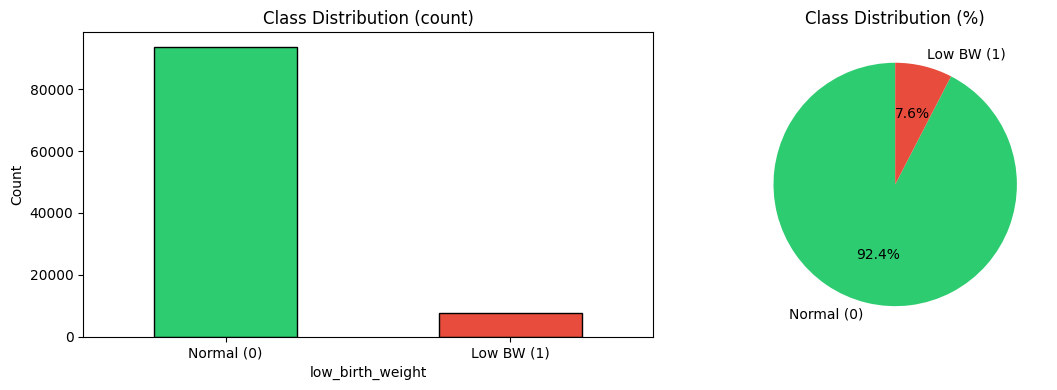

In [3]:
# ============================================================
# Cell 3 — Create Target Variable
# ============================================================
df['low_birth_weight'] = (df['BWEIGHT'] < 5.5).astype(int)
print("--- Target distribution ---")
print(df['low_birth_weight'].value_counts())
print(f"\nImbalance ratio: {df['low_birth_weight'].value_counts()[0] / df['low_birth_weight'].value_counts()[1]:.4f} : 1")

# Visualise class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['low_birth_weight'].value_counts().plot.bar(ax=axes[0], color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[0].set_title('Class Distribution (count)')
axes[0].set_xticklabels(['Normal (0)', 'Low BW (1)'], rotation=0)
axes[0].set_ylabel('Count')

df['low_birth_weight'].value_counts(normalize=True).plot.pie(
    ax=axes[1], autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'],
    labels=['Normal (0)', 'Low BW (1)'], startangle=90
)
axes[1].set_title('Class Distribution (%)')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()


In [4]:
# ============================================================
# Cell 4 — Drop Irrelevant / Leakage Columns
# ============================================================
df.drop(columns=['ID', 'BWEIGHT'], inplace=True)
print(f"Shape after dropping ID & BWEIGHT: {df.shape}")
print(f"Remaining columns: {df.columns.tolist()}")


Shape after dropping ID & BWEIGHT: (101400, 36)
Remaining columns: ['SEX', 'MARITAL', 'FAGE', 'GAINED', 'VISITS', 'MAGE', 'FEDUC', 'MEDUC', 'TOTALP', 'BDEAD', 'TERMS', 'LOUTCOME', 'WEEKS', 'RACEMOM', 'RACEDAD', 'HISPMOM', 'HISPDAD', 'CIGNUM', 'DRINKNUM', 'ANEMIA', 'CARDIAC', 'ACLUNG', 'DIABETES', 'HERPES', 'HYDRAM', 'HEMOGLOB', 'HYPERCH', 'HYPERPR', 'ECLAMP', 'CERVIX', 'PINFANT', 'PRETERM', 'RENAL', 'RHSEN', 'UTERINE', 'low_birth_weight']


In [5]:
# ============================================================
# Cell 5 — Identify column types
# ============================================================
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c != 'low_birth_weight']

medical_conditions = [
    'ANEMIA', 'CARDIAC', 'ACLUNG', 'DIABETES', 'HERPES', 'HYDRAM',
    'HEMOGLOB', 'HYPERCH', 'HYPERPR', 'ECLAMP', 'CERVIX', 'PINFANT',
    'PRETERM', 'RENAL', 'RHSEN', 'UTERINE'
]

print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")
print(f"Numeric columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Medical condition flags ({len(medical_conditions)}): {medical_conditions}")


Categorical columns (2): ['HISPMOM', 'HISPDAD']
Numeric columns (33): ['SEX', 'MARITAL', 'FAGE', 'GAINED', 'VISITS', 'MAGE', 'FEDUC', 'MEDUC', 'TOTALP', 'BDEAD', 'TERMS', 'LOUTCOME', 'WEEKS', 'RACEMOM', 'RACEDAD', 'CIGNUM', 'DRINKNUM', 'ANEMIA', 'CARDIAC', 'ACLUNG', 'DIABETES', 'HERPES', 'HYDRAM', 'HEMOGLOB', 'HYPERCH', 'HYPERPR', 'ECLAMP', 'CERVIX', 'PINFANT', 'PRETERM', 'RENAL', 'RHSEN', 'UTERINE']
Medical condition flags (16): ['ANEMIA', 'CARDIAC', 'ACLUNG', 'DIABETES', 'HERPES', 'HYDRAM', 'HEMOGLOB', 'HYPERCH', 'HYPERPR', 'ECLAMP', 'CERVIX', 'PINFANT', 'PRETERM', 'RENAL', 'RHSEN', 'UTERINE']


In [6]:
# ============================================================
# Cell 6 — Handle missing values
# ============================================================
print("Missing values BEFORE imputation:")
print(df.isnull().sum()[df.isnull().sum() > 0])

for col in numeric_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
        print(f"  Filled {col} NaNs with median = {median_val}")

for col in categorical_cols:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)
        print(f"  Filled {col} NaNs with mode = {mode_val}")

print(f"\nTotal missing after imputation: {df.isnull().sum().sum()}")


Missing values BEFORE imputation:
GAINED    1
FEDUC     1
WEEKS     1
CIGNUM    1
HYDRAM    1
dtype: int64
  Filled GAINED NaNs with median = 30.0
  Filled FEDUC NaNs with median = 12.0
  Filled WEEKS NaNs with median = 39.0
  Filled CIGNUM NaNs with median = 0.0
  Filled HYDRAM NaNs with median = 0.0

Total missing after imputation: 0


In [7]:
# ============================================================
# Cell 7 — Feature Engineering
# ============================================================
# --- (a) Interaction features between key medical conditions ---
df['HYPER_ECLAMP'] = df['HYPERPR'] * df['ECLAMP']       # pregnancy hypertension x eclampsia
df['HYPER_CHRONIC'] = df['HYPERCH'] * df['HYPERPR']     # chronic x pregnancy hypertension
df['DIABETES_HYPER'] = df['DIABETES'] * df['HYPERPR']   # diabetes x pregnancy hypertension
df['ANEMIA_CARDIAC'] = df['ANEMIA'] * df['CARDIAC']     # anemia x cardiac
df['PRETERM_CERVIX'] = df['PRETERM'] * df['CERVIX']     # previous preterm x incompetent cervix
df['UTERINE_HYDRAM'] = df['UTERINE'] * df['HYDRAM']    # uterine bleeding x hydramnios

# --- (b) Aggregate medical risk score ---
df['MEDICAL_RISK_SCORE'] = df[medical_conditions].sum(axis=1)
df['HAS_ANY_CONDITION'] = (df['MEDICAL_RISK_SCORE'] > 0).astype(int)
df['HIGH_RISK'] = (df['MEDICAL_RISK_SCORE'] >= 2).astype(int)  # 2+ conditions

# --- (c) Key numeric interactions ---
df['AGE_DIFF'] = df['FAGE'] - df['MAGE']               # father-mother age gap
df['EDUC_DIFF'] = df['FEDUC'] - df['MEDUC']            # education gap
df['MAGE_SQUARED'] = df['MAGE'] ** 2                    # quadratic maternal age
df['WEEKS_SQUARED'] = df['WEEKS'] ** 2                  # quadratic gestational weeks
df['VISITS_PER_WEEK'] = df['VISITS'] / (df['WEEKS'] + 1)  # visit rate
df['GAINED_PER_WEEK'] = df['GAINED'] / (df['WEEKS'] + 1)  # weight gain rate
df['CIG_DRINK_COMBO'] = df['CIGNUM'] + df['DRINKNUM']  # combined substance use

print(f"Shape after feature engineering: {df.shape}")
print(f"New features added: {df.shape[1] - 36}")
print(f"\nNew columns: {[c for c in df.columns if c not in numeric_cols + categorical_cols + ['low_birth_weight']]}")


Shape after feature engineering: (101400, 52)
New features added: 16

New columns: ['HYPER_ECLAMP', 'HYPER_CHRONIC', 'DIABETES_HYPER', 'ANEMIA_CARDIAC', 'PRETERM_CERVIX', 'UTERINE_HYDRAM', 'MEDICAL_RISK_SCORE', 'HAS_ANY_CONDITION', 'HIGH_RISK', 'AGE_DIFF', 'EDUC_DIFF', 'MAGE_SQUARED', 'WEEKS_SQUARED', 'VISITS_PER_WEEK', 'GAINED_PER_WEEK', 'CIG_DRINK_COMBO']


In [8]:
# ============================================================
# Cell 8 — Encode Categorical Columns & Feature Selection
# ============================================================
le_map = {}
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    le_map[col] = dict(zip(le.classes_, range(len(le.classes_))))
    print(f"  LabelEncoded {col}: {le_map[col]}")

# --- Correlation-based Feature Selection ---
CORR_THRESHOLD = 0.02
target = 'low_birth_weight'
corr = df.select_dtypes(include=[np.number]).corr()[target].drop(target).abs()
drop_cols = corr[corr < CORR_THRESHOLD].index.tolist()
keep_cols = corr[corr >= CORR_THRESHOLD].index.tolist()

print(f"\n--- Feature Selection (|corr| >= {CORR_THRESHOLD}) ---")
print(f"Dropped {len(drop_cols)} features: {drop_cols}")
print(f"Kept {len(keep_cols)} features: {keep_cols}")

df_filtered = df.drop(columns=drop_cols)
df_tree = df_filtered.copy()
# Re-identify remaining categorical columns for one-hot encoding
remaining_cat_cols = [c for c in categorical_cols if c in df_filtered.columns]
if remaining_cat_cols:
    df_linear = pd.get_dummies(df_filtered, columns=remaining_cat_cols, drop_first=True)
else:
    df_linear = df_filtered.copy()

print(f"\nTree-model DataFrame shape: {df_tree.shape}")
print(f"Linear-model DataFrame shape: {df_linear.shape}")


  LabelEncoded HISPMOM: {'C': 0, 'M': 1, 'N': 2, 'O': 3, 'P': 4, 'S': 5, 'U': 6}
  LabelEncoded HISPDAD: {'C': 0, 'M': 1, 'N': 2, 'O': 3, 'P': 4, 'S': 5, 'U': 6}

--- Feature Selection (|corr| >= 0.02) ---
Dropped 25 features: ['SEX', 'FAGE', 'MAGE', 'FEDUC', 'MEDUC', 'LOUTCOME', 'HISPMOM', 'HISPDAD', 'DRINKNUM', 'ANEMIA', 'CARDIAC', 'ACLUNG', 'DIABETES', 'HERPES', 'HEMOGLOB', 'PINFANT', 'RENAL', 'RHSEN', 'ANEMIA_CARDIAC', 'UTERINE_HYDRAM', 'AGE_DIFF', 'EDUC_DIFF', 'MAGE_SQUARED', 'VISITS_PER_WEEK', 'GAINED_PER_WEEK']
Kept 25 features: ['MARITAL', 'GAINED', 'VISITS', 'TOTALP', 'BDEAD', 'TERMS', 'WEEKS', 'RACEMOM', 'RACEDAD', 'CIGNUM', 'HYDRAM', 'HYPERCH', 'HYPERPR', 'ECLAMP', 'CERVIX', 'PRETERM', 'UTERINE', 'HYPER_ECLAMP', 'DIABETES_HYPER', 'PRETERM_CERVIX', 'MEDICAL_RISK_SCORE', 'HAS_ANY_CONDITION', 'HIGH_RISK', 'WEEKS_SQUARED', 'CIG_DRINK_COMBO']

Tree-model DataFrame shape: (101400, 27)
Linear-model DataFrame shape: (101400, 27)


In [9]:
# ============================================================
# Cell 9 — Define Features and Target
# ============================================================
target = 'low_birth_weight'
X = df_tree.drop(columns=[target])
y = df_tree[target]

# Compute scale_pos_weight for boosting models
neg_count = (y == 0).sum()
pos_count = (y == 1).sum()
scale_pos_weight = neg_count / pos_count

print(f"Features shape: {X.shape}")
print(f"Target shape:   {y.shape}")
print(f"scale_pos_weight = {scale_pos_weight:.4f}")


Features shape: (101400, 26)
Target shape:   (101400,)
scale_pos_weight = 12.1757


In [10]:
# ============================================================
# Cell 10 — Evaluation Helper Functions
# ============================================================
def calculate_metrics(y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    ba = balanced_accuracy_score(y_true, y_pred)
    return acc, prec, rec, f1, mcc, auc, ba

def print_fold_report(y_true, y_pred, fold_num=1):
    print(f"\n--- Classification Report (Fold {fold_num}) ---")
    print(classification_report(y_true, y_pred, target_names=['Normal Weight', 'Low Weight']))
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

def find_best_threshold(y_true, y_prob, metric='f1'):
    thresholds = np.arange(0.05, 0.96, 0.01)
    scores = [f1_score(y_true, (y_prob >= t).astype(int), zero_division=0) for t in thresholds]
    best_idx = np.argmax(scores)
    return thresholds[best_idx], scores[best_idx]

print("✅ Helper functions and plotting utilities defined.")


✅ Helper functions and plotting utilities defined.


In [11]:
# ============================================================
# Cell 11 — Optuna: Random Forest
# ============================================================

def objective_rf(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200),
        'max_depth': trial.suggest_int('max_depth', 5, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 20),
        'class_weight': 'balanced',
        'random_state': SEED,
        'n_jobs': -1
    }
    
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    f1_scores = []
    for train_idx, val_idx in skf.split(X, y):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        smote = SMOTE(random_state=SEED)
        X_tr_res, y_tr_res = smote.fit_resample(X_tr, y_tr)
        
        model = RandomForestClassifier(**params)
        model.fit(X_tr_res, y_tr_res)
        y_prob = model.predict_proba(X_val)[:, 1]
        
        best_t, best_score = find_best_threshold(y_val, y_prob)
        f1_scores.append(best_score)
    
    return np.mean(f1_scores)

print("Tuning Random Forest with Optuna...")
study_rf = optuna.create_study(direction='maximize', sampler=TPESampler(seed=SEED))
study_rf.optimize(objective_rf, n_trials=30, show_progress_bar=True)

print(f"\n✅ Best Random Forest F1: {study_rf.best_value:.4f}")
print(f"Best params: {study_rf.best_params}")


Tuning Random Forest with Optuna...


Best trial: 16. Best value: 0.580382: 100%|██████████| 30/30 [05:44<00:00, 11.49s/it]


✅ Best Random Forest F1: 0.5804
Best params: {'n_estimators': 155, 'max_depth': 5, 'min_samples_split': 18, 'min_samples_leaf': 4}


In [12]:
# ============================================================
# Cell 12 — Create Random Forest Model
# ============================================================

if 'study_rf' in globals() and hasattr(study_rf, 'best_params'):
    best_params_base = study_rf.best_params.copy()
    best_params_base['class_weight'] = 'balanced'
    best_params_base['random_state'] = SEED
    best_params_base['n_jobs'] = -1
    xgb_model = RandomForestClassifier(**best_params_base)
    print("✅ RandomForestClassifier created successfully using optimal hyperparameters from Optuna.")
else:
    xgb_model = RandomForestClassifier(random_state=SEED, class_weight='balanced', max_depth=10, n_estimators=100, n_jobs=-1)
    print("✅ RandomForestClassifier created successfully using default hyperparameters.")

print(f"\nModel parameters:\n{xgb_model.get_params()}")


✅ RandomForestClassifier created successfully using optimal hyperparameters from Optuna.

Model parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 5, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 4, 'min_samples_split': 18, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 155, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [13]:
# ============================================================
# Cell 13 — 5-Fold Stratified CV (SMOTE on Training Fold, No Data Leakage)
# ============================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_metrics = []
train_fold_metrics = []
ya_sm_list = []          # true labels (all folds)
ba_sm_list = []          # predicted probabilities (all folds)
y_pred_all_list = []     # predicted labels (all folds)

print("Starting 5-Fold Stratified Cross-Validation (SMOTE inside folds) ...\n")
print("=" * 80)

if 'study_rf' in globals() and hasattr(study_rf, 'best_params'):
    best_params = study_rf.best_params.copy()
    best_params['class_weight'] = 'balanced'
    best_params['random_state'] = 42
    best_params['n_jobs'] = -1
    print("Using optimal hyperparameters found by Optuna:")
    print(best_params)
else:
    best_params = {
        'random_state': 42,
        'class_weight': 'balanced',
        'max_depth': 10,
        'n_estimators': 100,
        'n_jobs': -1
    }
    print("Using default hyperparameters:")
    print(best_params)

for fold, (train_idx, val_idx) in enumerate(cv.split(X, y), start=1):
    X_train_fold, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train_fold, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # --- Apply standard SMOTE only on the training fold (No Data Leakage) ---
    smote = SMOTE(random_state=SEED)
    X_train_res, y_train_res = smote.fit_resample(X_train_fold, y_train_fold)

    # --- Train ---
    model = RandomForestClassifier(**best_params)
    model.fit(X_train_res, y_train_res)

    # --- Validation predictions (on original unresampled val fold) ---
    y_prob = model.predict_proba(X_val)[:, 1]
    best_t, _ = find_best_threshold(y_val, y_prob)
    y_pred = (y_prob >= best_t).astype(int)

    # --- Validation metrics ---
    acc, prec, rec, f1, mcc, auc, ba = calculate_metrics(y_val, y_pred, y_prob)

    fold_metrics.append({
        'fold': fold, 'accuracy': acc, 'precision': prec,
        'recall': rec, 'f1': f1, 'mcc': mcc,
        'roc_auc': auc, 'balanced_accuracy': ba
    })

    # --- Training metrics (on ORIGINAL UNRESAMPLED train fold) ---
    y_train_prob = model.predict_proba(X_train_fold)[:, 1]
    y_train_pred = (y_train_prob >= best_t).astype(int)

    train_acc  = accuracy_score(y_train_fold, y_train_pred)
    train_prec = precision_score(y_train_fold, y_train_pred, zero_division=0)
    train_rec  = recall_score(y_train_fold, y_train_pred, zero_division=0)
    train_f1   = f1_score(y_train_fold, y_train_pred, zero_division=0)
    train_auc  = roc_auc_score(y_train_fold, y_train_prob)

    train_fold_metrics.append({
        'fold': fold, 'accuracy': train_acc, 'precision': train_prec,
        'recall': train_rec, 'f1': train_f1, 'roc_auc': train_auc
    })

    # --- Store predictions ---
    ya_sm_list.extend(y_val.tolist())
    ba_sm_list.extend(y_prob.tolist())
    y_pred_all_list.extend(y_pred.tolist())

    print(f"         Val  — Acc: {acc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f} "
          f"| F1: {f1:.4f} | MCC: {mcc:.4f} | AUC: {auc:.4f} | BA: {ba:.4f} (Threshold: {best_t:.2f})")
    print(f"         Train— Acc: {train_acc:.4f} | Prec: {train_prec:.4f} | Rec: {train_rec:.4f} "
          f"| F1: {train_f1:.4f} | AUC: {train_auc:.4f}")
    print("-" * 80)

# --- Aggregate DataFrames ---
df_val_metrics   = pd.DataFrame(fold_metrics)
df_train_metrics = pd.DataFrame(train_fold_metrics)

# --- Aggregated confusion matrix ---
cm_all = confusion_matrix(ya_sm_list, y_pred_all_list)
overall_auc = roc_auc_score(ya_sm_list, ba_sm_list)
print(f"\nOverall AUC (aggregated): {overall_auc:.4f}")
print(f"Aggregated Confusion Matrix:\n{cm_all}")

# --- Final model on full resampled dataset ---
smote_full = SMOTE(random_state=SEED)
X_full_res, y_full_res = smote_full.fit_resample(X, y)
final_model = RandomForestClassifier(**best_params)
final_model.fit(X_full_res, y_full_res)
print("\n✅ Final model trained on full resampled dataset.")


Starting 5-Fold Stratified Cross-Validation (SMOTE inside folds) ...

Using optimal hyperparameters found by Optuna:
{'n_estimators': 155, 'max_depth': 5, 'min_samples_split': 18, 'min_samples_leaf': 4, 'class_weight': 'balanced', 'random_state': 42, 'n_jobs': -1}
         Val  — Acc: 0.9374 | Prec: 0.5932 | Rec: 0.5578 | F1: 0.5750 | MCC: 0.5415 | AUC: 0.8840 | BA: 0.7632 (Threshold: 0.79)
         Train— Acc: 0.9387 | Prec: 0.6031 | Rec: 0.5617 | F1: 0.5817 | AUC: 0.8953
--------------------------------------------------------------------------------
         Val  — Acc: 0.9360 | Prec: 0.5774 | Rec: 0.5867 | F1: 0.5820 | MCC: 0.5474 | AUC: 0.8934 | BA: 0.7757 (Threshold: 0.75)
         Train— Acc: 0.9354 | Prec: 0.5726 | Rec: 0.5858 | F1: 0.5792 | AUC: 0.8909
--------------------------------------------------------------------------------
         Val  — Acc: 0.9363 | Prec: 0.5798 | Rec: 0.5854 | F1: 0.5826 | MCC: 0.5482 | AUC: 0.8902 | BA: 0.7753 (Threshold: 0.77)
         Train— Ac

OVERFITTING ANALYSIS — Train vs Validation per Fold (Unresampled Train)


Gap (Train−Val)                                      Train          \
Metric        accuracy      f1 precision  recall roc_auc accuracy      f1   
Fold                                                                        
1               0.0013  0.0067    0.0098  0.0039  0.0113   0.9387  0.5817   
2              -0.0007 -0.0029   -0.0047 -0.0009 -0.0025   0.9354  0.5792   
3              -0.0007 -0.0042   -0.0050 -0.0033  0.0034   0.9356  0.5784   
4              -0.0006 -0.0063   -0.0029 -0.0100  0.0005   0.9343  0.5784   
5              -0.0000  0.0030   -0.0013  0.0075 -0.0017   0.9352  0.5807   

                                 Validation                                    
Metric precision  recall roc_auc   accuracy      f1 precision  recall roc_auc  
Fold                                                                           
1         0.6031  0.5617  0.8953     0.9374  0.5750    0.5932  0.5578  0.8840  
2         0.5726  0.5858  0.8909     0.9360  0.5820    0.5774  0.5867  0.8934  
3         0.5748  0.5821  0.8937     0.9363  0.5826    0.5798  0.5854  0.8902  
4         0.5639  0.5936  0.8924     0.9349  0.5846    0.5668  0.6036  0.8919  
5         0.5706  0.5910  0.8915     0.9353  0.5777    0.5720  0.5835  0.8932


--- Mean across folds ---
      accuracy  |  Train: 0.9358  |  Val: 0.9360  |  Gap: -0.0002
     precision  |  Train: 0.5770  |  Val: 0.5778  |  Gap: -0.0008
        recall  |  Train: 0.5829  |  Val: 0.5834  |  Gap: -0.0006
            f1  |  Train: 0.5797  |  Val: 0.5804  |  Gap: -0.0007
       roc_auc  |  Train: 0.8928  |  Val: 0.8906  |  Gap: 0.0022

Overall average gap: -0.0000

>>> GOOD: No significant overfitting ✅


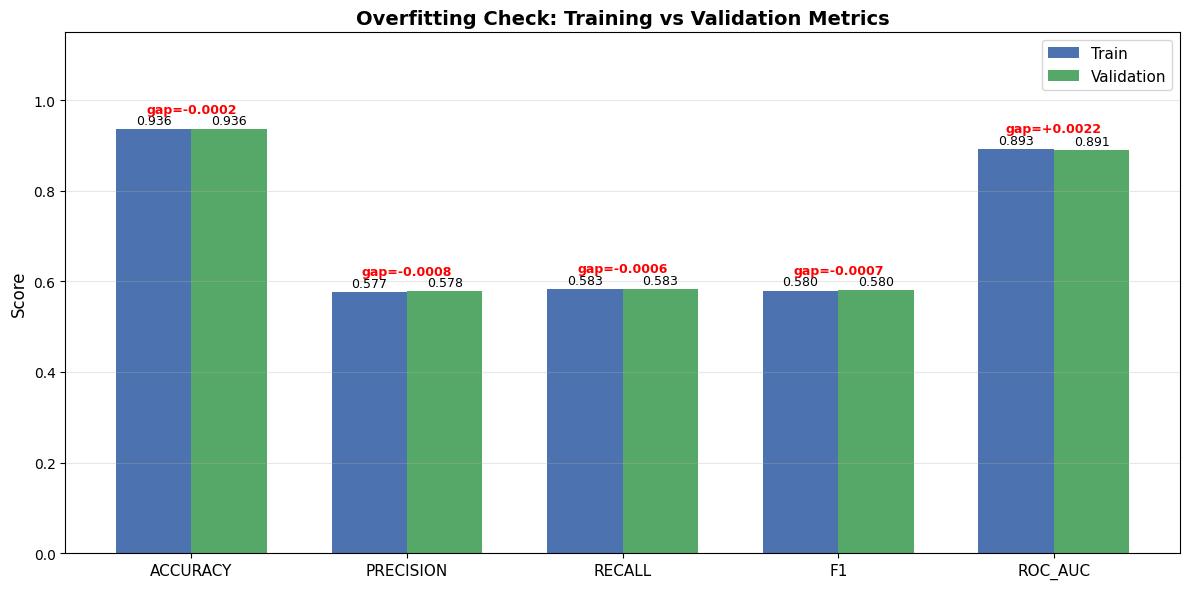

In [14]:
# ============================================================
# Cell 14 — Overfitting Analysis
# ============================================================
compare_metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

rows = []
for i in range(len(df_train_metrics)):
    fold_num = i + 1
    for m in compare_metrics:
        t_val = df_train_metrics.loc[i, m]
        v_val = df_val_metrics.loc[i, m]
        rows.append({
            'Fold': fold_num,
            'Metric': m,
            'Train': t_val,
            'Validation': v_val,
            'Gap (Train−Val)': t_val - v_val
        })

df_overfit = pd.DataFrame(rows)
print("=" * 75)
print("OVERFITTING ANALYSIS — Train vs Validation per Fold (Unresampled Train)")
print("=" * 75)
display(df_overfit.pivot_table(
    index='Fold',
    columns='Metric',
    values=['Train', 'Validation', 'Gap (Train\u2212Val)']
).round(4))

# Mean summary
print("\n--- Mean across folds ---")
for m in compare_metrics:
    subset = df_overfit[df_overfit['Metric'] == m]
    print(f"  {m:>12s}  |  Train: {subset['Train'].mean():.4f}  |  "
          f"Val: {subset['Validation'].mean():.4f}  |  "
          f"Gap: {subset['Gap (Train\u2212Val)'].mean():.4f}")

avg_gap = df_overfit['Gap (Train\u2212Val)'].mean()
print(f"\nOverall average gap: {avg_gap:.4f}")

if avg_gap > 0.15:
    verdict = "WARNING: Model shows significant overfitting \u26a0\ufe0f"
elif avg_gap > 0.05:
    verdict = "MODERATE: Some overfitting detected \u26a0\ufe0f"
else:
    verdict = "GOOD: No significant overfitting \u2705"
print(f"\n>>> {verdict}")

# --- Grouped bar chart ---
mean_train = [df_train_metrics[m].mean() for m in compare_metrics]
mean_val   = [df_val_metrics[m].mean()   for m in compare_metrics]
mean_gaps  = [t - v for t, v in zip(mean_train, mean_val)]

x_pos = np.arange(len(compare_metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
bars_train = ax.bar(x_pos - width/2, mean_train, width, label='Train', color='#4c72b0')
bars_val   = ax.bar(x_pos + width/2, mean_val,   width, label='Validation', color='#55a868')

# Annotate gap on top of validation bars
for idx, (bt, bv, gap) in enumerate(zip(bars_train, bars_val, mean_gaps)):
    ax.text(bt.get_x() + bt.get_width()/2, bt.get_height() + 0.005,
            f'{bt.get_height():.3f}', ha='center', va='bottom', fontsize=9)
    ax.text(bv.get_x() + bv.get_width()/2, bv.get_height() + 0.005,
            f'{bv.get_height():.3f}', ha='center', va='bottom', fontsize=9)
    mid_x = (bt.get_x() + bv.get_x() + bv.get_width()) / 2
    ax.text(mid_x, max(bt.get_height(), bv.get_height()) + 0.03,
            f'gap={gap:+.4f}', ha='center', va='bottom',
            fontsize=9, fontweight='bold', color='red')

ax.set_xticks(x_pos)
ax.set_xticklabels([m.upper() for m in compare_metrics], fontsize=11)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Overfitting Check: Training vs Validation Metrics',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim(0, 1.15)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



 Retraining on all data for feature importance visualization...


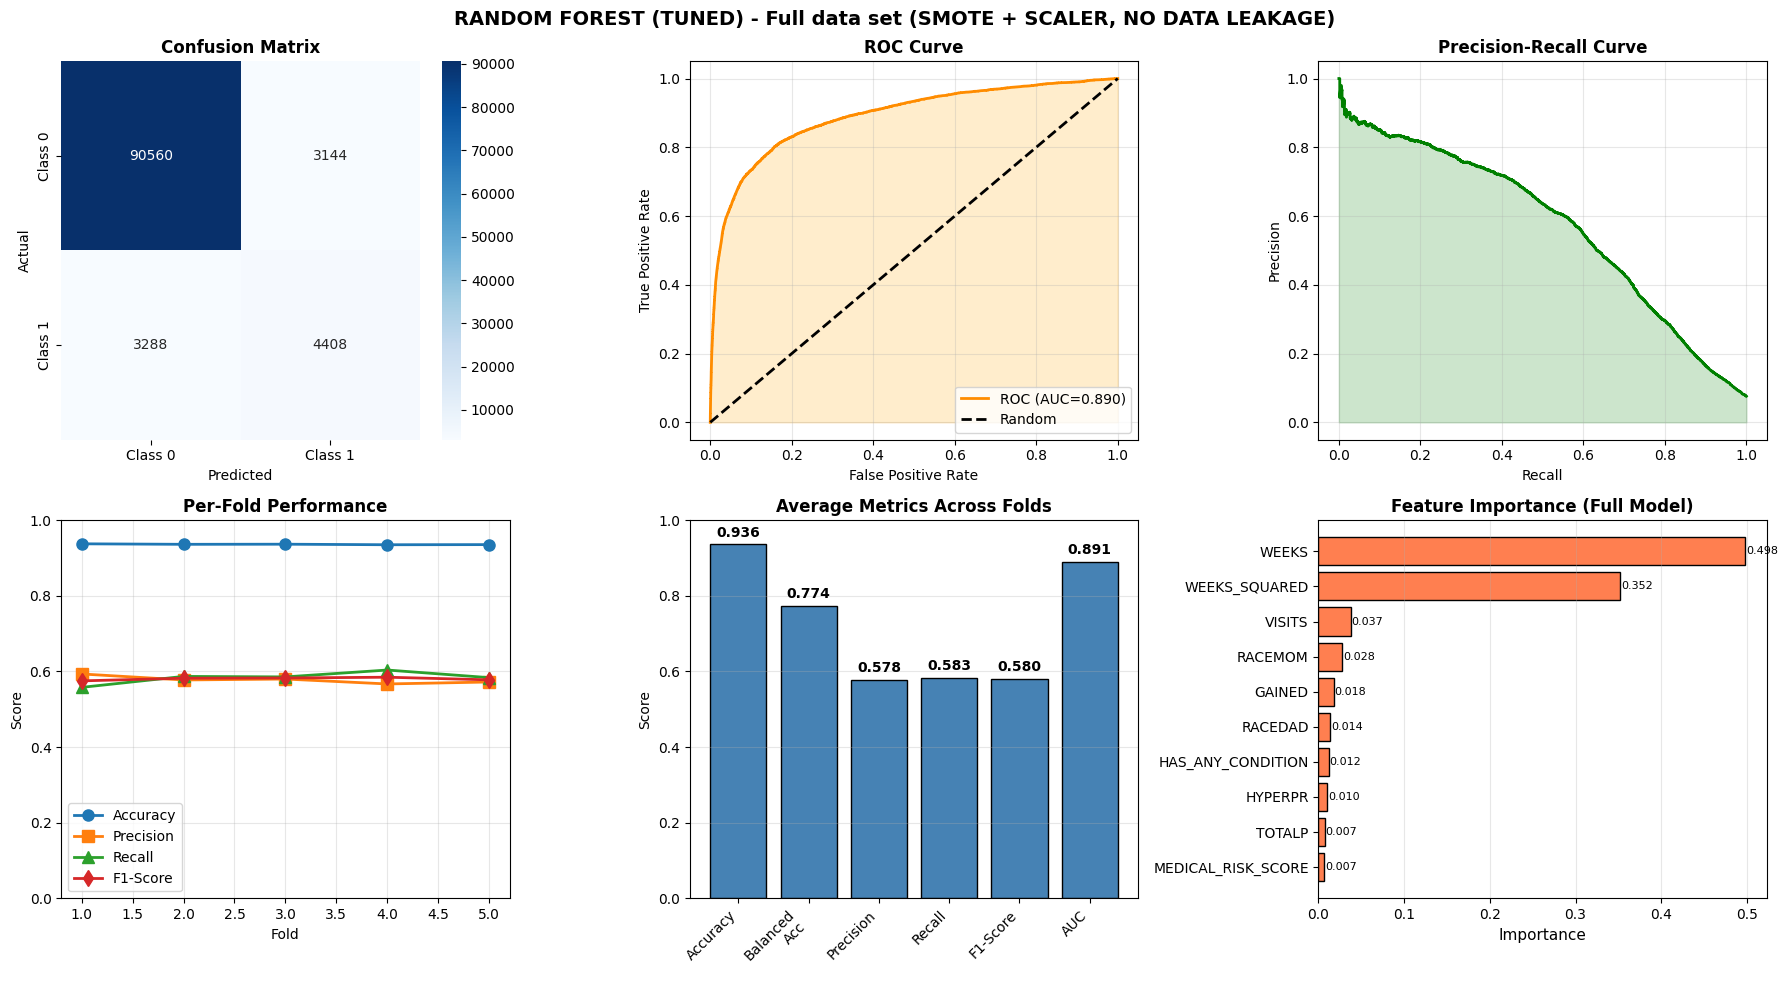

In [15]:
MODEL_TITLE = 'RANDOM FOREST (TUNED)'
cm_ov = cm_all
y_true_all = ya_sm_list
y_prob_all = ba_sm_list
ov_auc = overall_auc
fold_summary = df_val_metrics.rename(columns={'fold':'Fold', 'accuracy':'Accuracy', 'precision':'Precision', 'recall':'Recall', 'f1':'F1_Score', 'balanced_accuracy':'Balanced_Acc', 'roc_auc':'AUC'})
X_original = X
y_original = y
feature_names = X.columns

best_thresh, _ = find_best_threshold(y_true_all, y_prob_all)
cm_ov = confusion_matrix(y_true_all, (np.array(y_prob_all) >= best_thresh).astype(int))

# Retraining on all data for feature importance visualization
if 'study_rf' in globals() and hasattr(study_rf, 'best_params'):
    best_params_fi = study_rf.best_params.copy()
    best_params_fi['class_weight'] = 'balanced'
    best_params_fi['random_state'] = 42
    best_params_fi['n_jobs'] = -1
    clf_model = RandomForestClassifier(**best_params_fi)
else:
    clf_model = RandomForestClassifier(random_state=42, class_weight='balanced', max_depth=10, n_estimators=100, n_jobs=-1)

# ============================================================
# Cell 10 — 6-Chart Comprehensive Visualization
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve
import pandas as pd
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(f'{MODEL_TITLE} - Full data set (SMOTE + SCALER, NO DATA LEAKAGE)', fontsize=14, fontweight='bold')

sns.heatmap(cm_ov, annot=True, fmt='d', cmap='Blues', ax=axes[0,0],
            xticklabels=['Class 0','Class 1'], yticklabels=['Class 0','Class 1'])
axes[0,0].set_title('Confusion Matrix', fontsize=12, fontweight='bold')
axes[0,0].set_xlabel('Predicted'); axes[0,0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_true_all, y_prob_all)
axes[0,1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC={ov_auc:.3f})')
axes[0,1].plot([0,1],[0,1],'k--',lw=2,label='Random')
axes[0,1].fill_between(fpr, tpr, alpha=0.2, color='orange')
axes[0,1].set_xlabel('False Positive Rate'); axes[0,1].set_ylabel('True Positive Rate')
axes[0,1].set_title('ROC Curve', fontsize=12, fontweight='bold')
axes[0,1].legend(loc='lower right'); axes[0,1].grid(True, alpha=0.3)

pvals, rvals, _ = precision_recall_curve(y_true_all, y_prob_all)
axes[0,2].plot(rvals, pvals, color='green', lw=2)
axes[0,2].fill_between(rvals, pvals, alpha=0.2, color='green')
axes[0,2].set_xlabel('Recall'); axes[0,2].set_ylabel('Precision')
axes[0,2].set_title('Precision-Recall Curve', fontsize=12, fontweight='bold')
axes[0,2].grid(True, alpha=0.3)

fds = fold_summary['Fold']
axes[1,0].plot(fds, fold_summary['Accuracy'],'o-',label='Accuracy',lw=2,ms=8)
axes[1,0].plot(fds, fold_summary['Precision'],'s-',label='Precision',lw=2,ms=8)
axes[1,0].plot(fds, fold_summary['Recall'],'^-',label='Recall',lw=2,ms=8)
axes[1,0].plot(fds, fold_summary['F1_Score'],'d-',label='F1-Score',lw=2,ms=8)
axes[1,0].set_xlabel('Fold'); axes[1,0].set_ylabel('Score')
axes[1,0].set_title('Per-Fold Performance', fontsize=12, fontweight='bold')
axes[1,0].set_ylim(0,1); axes[1,0].legend(loc='best'); axes[1,0].grid(True, alpha=0.3)

avg_m = {'Accuracy': fold_summary['Accuracy'].mean(),
         'Balanced\nAcc': fold_summary['Balanced_Acc'].mean(),
         'Precision': fold_summary['Precision'].mean(),
         'Recall': fold_summary['Recall'].mean(),
         'F1-Score': fold_summary['F1_Score'].mean(),
         'AUC': fold_summary['AUC'].mean()}
bars = axes[1,1].bar(avg_m.keys(), avg_m.values(), color='steelblue', edgecolor='black')
axes[1,1].set_ylim(0,1); axes[1,1].set_ylabel('Score')
axes[1,1].set_title('Average Metrics Across Folds', fontsize=12, fontweight='bold')
axes[1,1].set_xticklabels(list(avg_m.keys()), rotation=45, ha='right')
for bar, val in zip(bars, avg_m.values()):
    axes[1,1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02, f'{val:.3f}', ha='center', fontweight='bold')
axes[1,1].grid(True, alpha=0.3, axis='y')

print("\n Retraining on all data for feature importance visualization...")
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from collections import Counter

scaler_full = StandardScaler()
X_full_scaled = scaler_full.fit_transform(X_original)
cc_before = Counter(y_original)
smote_full = SMOTE(random_state=42, k_neighbors=min(5, int(cc_before[1]) - 1))
X_full_resampled, y_full_resampled = smote_full.fit_resample(X_full_scaled, y_original)

clf = clf_model
clf.fit(X_full_resampled, y_full_resampled)

# Helper function to extract feature importances
def get_fi(model, names):
    import pandas as pd
    if hasattr(model, 'feature_importances_'):
        imp = model.feature_importances_
    elif hasattr(model, 'coef_'):
        imp = np.abs(model.coef_[0])
    elif hasattr(model, 'best_estimator_'):
        underlying = model.best_estimator_
        if hasattr(underlying, 'coef_'):
            imp = np.abs(underlying.coef_[0])
        elif hasattr(underlying, 'feature_importances_'):
            imp = underlying.feature_importances_
        else:
            imp = np.zeros(len(names))
    elif hasattr(model, 'calibrated_classifiers_'):
        imps = []
        for c in model.calibrated_classifiers_:
            if hasattr(c.estimator, 'coef_'):
                imps.append(np.abs(c.estimator.coef_[0]))
            elif hasattr(c.estimator, 'feature_importances_'):
                imps.append(c.estimator.feature_importances_)
        if imps:
            imp = np.mean(imps, axis=0)
        else:
            imp = np.zeros(len(names))
    else:
        imp = np.zeros(len(names))
        
    df_fi = pd.DataFrame({'Feature': names, 'Importance': imp})
    return df_fi.sort_values('Importance', ascending=True).tail(10)

fi = get_fi(clf, feature_names)
axes[1,2].barh(fi['Feature'], fi['Importance'], color='coral', edgecolor='black')
axes[1,2].set_xlabel('Importance', fontsize=11)
axes[1,2].set_title('Feature Importance (Full Model)', fontsize=12, fontweight='bold')
axes[1,2].grid(True, alpha=0.3, axis='x')
for i, v in enumerate(fi['Importance']):
    axes[1,2].text(v + 0.001, i, f'{v:.3f}', va='center', fontsize=8)

plt.tight_layout()
plt.show()


In [16]:
# ============================================================
# Cell 16 — Summary Statistics
# ============================================================
print("\n" + "=" * 65)
print("       FINAL SUMMARY")
print("=" * 65)

summary_metrics = ['accuracy', 'precision', 'recall', 'f1',
                   'mcc', 'roc_auc', 'balanced_accuracy']

print(f"{'Metric':<22s} {'Mean':>8s}  \u00b1  {'Std':>8s}")
print("-" * 45)
for m in summary_metrics:
    mean_v = df_val_metrics[m].mean()
    std_v  = df_val_metrics[m].std()
    print(f"{m:<22s} {mean_v:>8.4f}  \u00b1  {std_v:>8.4f}")

print(f"\n{'Overall AUC (agg.)':<22s} {overall_auc:>8.4f}")

print("\n--- Aggregated Confusion Matrix ---")
tn, fp, fn, tp = cm_all.ravel()
print(f"  TN = {tn:,}   FP = {fp:,}")
print(f"  FN = {fn:,}   TP = {tp:,}")

print(f"\n>>> Overfitting verdict: {verdict}")
print("=" * 65)



       FINAL SUMMARY
Metric                     Mean  ±       Std
---------------------------------------------
accuracy                 0.9360  ±    0.0010
precision                0.5778  ±    0.0100
recall                   0.5834  ±    0.0164
f1                       0.5804  ±    0.0040
mcc                      0.5459  ±    0.0036
roc_auc                  0.8906  ±    0.0039
balanced_accuracy        0.7742  ±    0.0071

Overall AUC (agg.)       0.8903

--- Aggregated Confusion Matrix ---
  TN = 90,419   FP = 3,285
  FN = 3,206   TP = 4,490

>>> Overfitting verdict: GOOD: No significant overfitting ✅


In [17]:
# ============================================================
# Cell 17 — Save Model Artifacts
# ============================================================
from shared.model_artifacts import save_model_artifacts
from sklearn.pipeline import Pipeline as SkPipeline

# Wrap final_model into a sklearn Pipeline for artifact saving
pipeline = SkPipeline(steps=[
    ('model', final_model),
])

# Best threshold from aggregated OOF predictions
best_thresh, _ = find_best_threshold(ya_sm_list, ba_sm_list)

# Aggregate train metrics (mean across folds)
train_metrics = {
    'accuracy':  float(df_train_metrics['accuracy'].mean()),
    'precision': float(df_train_metrics['precision'].mean()),
    'recall':    float(df_train_metrics['recall'].mean()),
    'f1':        float(df_train_metrics['f1'].mean()),
    'roc_auc':   float(df_train_metrics['roc_auc'].mean()),
}

# Aggregate validation metrics (mean across folds)
y_true_all = np.array(ya_sm_list)
y_prob_all = np.array(ba_sm_list)
y_pred_all = (y_prob_all >= best_thresh).astype(int)

test_metrics = {
    'accuracy':  float(accuracy_score(y_true_all, y_pred_all)),
    'precision': float(precision_score(y_true_all, y_pred_all, zero_division=0)),
    'recall':    float(recall_score(y_true_all, y_pred_all, zero_division=0)),
    'f1':        float(f1_score(y_true_all, y_pred_all, zero_division=0)),
    'roc_auc':   float(roc_auc_score(y_true_all, y_prob_all)),
}

report = classification_report(y_true_all, y_pred_all, output_dict=True, zero_division=0)
cm = confusion_matrix(y_true_all, y_pred_all).tolist()

metrics_payload = {
    "metrics": test_metrics,
    "classification_report": report,
    "confusion_matrix": cm,
}

# Categorical features that survived feature selection
cat_features = [c for c in remaining_cat_cols if c in X.columns]

save_model_artifacts(
    pipeline=pipeline,
    outcome="lbw",
    outcome_id="lbw",
    algorithm="random_forest",
    label="Random Forest",
    description="Random Forest classifier for low birth weight prediction with SMOTE resampling.",
    target_column="low_birth_weight",
    feature_order=X.columns.tolist(),
    categorical_features=cat_features,
    metrics_payload=metrics_payload,
    positive_label="Low Birth Weight (1)",
    negative_label="Normal Weight (0)",
    threshold=best_thresh,
    y_test=y_true_all,
    y_prob=y_prob_all,
    train_metrics=train_metrics,
    project_root=PROJECT_ROOT,
)


  [OK] Feature importance extracted (26/26 features)
  [OK] ROC and PR curves generated
  [OK] Overfitting analysis: Well Generalized (avg gap: +0.0013)

Artifacts saved:
 - c:\Users\USER\Desktop\AI_based_Birth_Cohort_Study\backend\models\lbw\random_forest\model.pkl
 - c:\Users\USER\Desktop\AI_based_Birth_Cohort_Study\backend\models\lbw\random_forest\meta.json
 - c:\Users\USER\Desktop\AI_based_Birth_Cohort_Study\backend\models\lbw\random_forest\metrics.json
 - c:\Users\USER\Desktop\AI_based_Birth_Cohort_Study\backend\models\lbw\registry.json
